# 1. Data ingestion and pre-processsing

# Task 1: Data ingestion and pre-processsing

Installing PySpark

In [ ]:
!pip install pyspark

Starting a Spark session

In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.Builder().appName("FraudDetectionProject").getOrCreate()
spark

##1.Loading the dataset

In [ ]:
spark.read.option('header','true').csv('card_transdata.csv').show(5)
df = spark.read.option('header','true').csv('card_transdata.csv', inferSchema=True)

+------------------+------------------------------+------------------------------+---------------+---------+---------------+------------+-----+
|distance_from_home|distance_from_last_transaction|ratio_to_median_purchase_price|repeat_retailer|used_chip|used_pin_number|online_order|fraud|
+------------------+------------------------------+------------------------------+---------------+---------+---------------+------------+-----+
| 57.87785658389723|            0.3111400080477545|            1.9459399775518593|            1.0|      1.0|            0.0|         0.0|  0.0|
|10.829942699255545|           0.17559150228166587|            1.2942188106198573|            1.0|      0.0|            0.0|         0.0|  0.0|
| 5.091079490616996|            0.8051525945853258|           0.42771456119427587|            1.0|      0.0|            0.0|         1.0|  0.0|
|2.2475643282963613|              5.60004354707232|           0.36266257805709584|            1.0|      1.0|            0.0|         1.0

##1.2. Data cleaning

### 1.2.1. Handling missing values

In [ ]:
print(f"There are {df.count()} rows in total")

There are 536110 rows in total


In [ ]:
from pyspark.sql.functions import col,sum

df.select(*(sum(col(c).isNull().cast("int")).alias(c) for c in df.columns)).show()

+------------------+------------------------------+------------------------------+---------------+---------+---------------+------------+-----+
|distance_from_home|distance_from_last_transaction|ratio_to_median_purchase_price|repeat_retailer|used_chip|used_pin_number|online_order|fraud|
+------------------+------------------------------+------------------------------+---------------+---------+---------------+------------+-----+
|                 0|                             0|                             0|              0|        0|              0|           0|    0|
+------------------+------------------------------+------------------------------+---------------+---------+---------------+------------+-----+



In [ ]:
df=df.dropna()

In [ ]:
print(f"The number of remaining rows is { df.count()}")

The number of remaining rows is 536110


In [ ]:
df.select(*(sum(col(c).isNull().cast("int")).alias(c) for c in df.columns)).show()


+------------------+------------------------------+------------------------------+---------------+---------+---------------+------------+-----+
|distance_from_home|distance_from_last_transaction|ratio_to_median_purchase_price|repeat_retailer|used_chip|used_pin_number|online_order|fraud|
+------------------+------------------------------+------------------------------+---------------+---------+---------------+------------+-----+
|                 0|                             0|                             0|              0|        0|              0|           0|    0|
+------------------+------------------------------+------------------------------+---------------+---------+---------------+------------+-----+



There is no missing values anymore

###1.2.2. Removing duplicates

In [ ]:
total_rows = df.count()
distinct_rows = df.distinct().count()

if total_rows > distinct_rows:
  print(f"Duplicates exist: Total rows = {total_rows}, Distinct rows = {distinct_rows}")
  df = df.dropDuplicates()
  print(f"Duplicates removed: Total rows = {df.count()}")
else:
  print("No duplicates were found")

No duplicates were found


###1.2.3. Ensuring correct data types

Checking the data types

In [ ]:
df.printSchema()

root
 |-- distance_from_home: double (nullable = true)
 |-- distance_from_last_transaction: double (nullable = true)
 |-- ratio_to_median_purchase_price: double (nullable = true)
 |-- repeat_retailer: double (nullable = true)
 |-- used_chip: double (nullable = true)
 |-- used_pin_number: double (nullable = true)
 |-- online_order: double (nullable = true)
 |-- fraud: double (nullable = true)



Converting the categorical/binary variables into the integer type

In [ ]:
binary_col = ['repeat_retailer', 'used_chip','used_pin_number','online_order','fraud']

for column in binary_col:
  df = df.withColumn(column, df[column].cast('int'))

In [ ]:
df.printSchema()

root
 |-- distance_from_home: double (nullable = true)
 |-- distance_from_last_transaction: double (nullable = true)
 |-- ratio_to_median_purchase_price: double (nullable = true)
 |-- repeat_retailer: integer (nullable = true)
 |-- used_chip: integer (nullable = true)
 |-- used_pin_number: integer (nullable = true)
 |-- online_order: integer (nullable = true)
 |-- fraud: integer (nullable = true)



##1.3. Transforming the data

###1.3.1. Feature scaling

Converting the columns with continous features  into a single vector column ( required to use Spark ML)

In [ ]:
from pyspark.ml.feature import VectorAssembler

#selecting only the behavioral distance features
distance_assembler = VectorAssembler(inputCols =['distance_from_home','distance_from_last_transaction'],
                            outputCol = 'distance_vector')

df = distance_assembler.transform(df)

Applying StandardScaler

In [ ]:
from pyspark.ml.feature import StandardScaler

standard_scaler = StandardScaler(
    inputCol="distance_vector",
    outputCol="scaled_distances",
    withStd=True,
    withMean=True
)

standard_model = standard_scaler.fit(df)
df = standard_model.transform(df)

###1.3.2. Normalizing transaction amounts

Putting it in a vector format

In [ ]:
ratio_assembler = VectorAssembler(inputCols =['ratio_to_median_purchase_price'],
                                  outputCol = 'ratio_vector')

df = ratio_assembler.transform(df)

Applying MinMaxScaler

In [ ]:
from pyspark.ml.feature import MinMaxScaler

minmax_scaler = MinMaxScaler(
    inputCol="ratio_vector",
    outputCol="normalized_ratio"
)

minmax_model= minmax_scaler.fit(df)
df = minmax_model.transform(df)

Creating a final vector which groups the scaled and normalized feature for ML enginering

In [ ]:
final_assembler = VectorAssembler(inputCols =['scaled_distances','normalized_ratio'],
                                  outputCol='final_features')

df = final_assembler.transform(df)

In [ ]:
df.select('distance_vector','scaled_distances','ratio_vector','normalized_ratio','final_features').show(5)

+--------------------+--------------------+--------------------+--------------------+--------------------+
|     distance_vector|    scaled_distances|        ratio_vector|    normalized_ratio|      final_features|
+--------------------+--------------------+--------------------+--------------------+--------------------+
|[57.8778565838972...|[0.47730751900389...|[1.9459399775518593]|[0.00725000486034...|[0.47730751900389...|
|[10.8299426992555...|[-0.2416451282282...|[1.2942188106198573]|[0.00481638009238...|[-0.2416451282282...|
|[5.09107949061699...|[-0.3293423406078...|[0.42771456119427...|[0.00158072302009...|[-0.3293423406078...|
|[2.24756432829636...|[-0.3727949102245...|[0.36266257805709...|[0.00133780914004...|[-0.3727949102245...|
|[44.1909360026183...|[0.26815376548158...|[2.2227672978404707]| [0.008283719671661]|[0.26815376548158...|
+--------------------+--------------------+--------------------+--------------------+--------------------+
only showing top 5 rows


#Task 2: Exploratory data analysis (EDA)

##2.1. Descriptive statistics

###For double features

Mean and Stadard deviation

In [ ]:
from pyspark.sql.functions import mean,stddev

df.select(
    #for distane from home
    mean('distance_from_home').alias('mean_distance_from_home'),
    stddev('distance_from_home').alias('std_distance_from_home'),
    #for distance from last transaction
    mean('distance_from_last_transaction').alias('mean_distance_from_last_transaction'),
    stddev('distance_from_last_transaction').alias('std_distance_from_last'),
    #for ratio_to_median_purchase_price
    mean('ratio_to_median_purchase_price').alias('mean_ratio_to_median_purchase_price'),
    stddev('ratio_to_median_purchase_price').alias('std_ratio_to_median_purchase_price')
).show()

+-----------------------+----------------------+-----------------------------------+----------------------+-----------------------------------+----------------------------------+
|mean_distance_from_home|std_distance_from_home|mean_distance_from_last_transaction|std_distance_from_last|mean_ratio_to_median_purchase_price|std_ratio_to_median_purchase_price|
+-----------------------+----------------------+-----------------------------------+----------------------+-----------------------------------+----------------------------------+
|     26.643083143617623|     65.43951686632724|                  5.029533142660329|    27.714506614518776|                  1.826082394286471|                2.8182594355826347|
+-----------------------+----------------------+-----------------------------------+----------------------+-----------------------------------+----------------------------------+



##Understanding:
The  data is highly dispersed, there may be outliers and the distribution is likely right skewed. This is concluded ad the std is sigificantly larger than the mean especially for the distance features.Most transactions happen close to home and at small distances, but fraudulent transactions may occur at unusually large distances — pulling the standard deviation upward.  As of the ration to meadian purchase the transcation as around 1.8 but the std indicates 2.7 some fraudenlent transactions may involde unusually high spending amounts

The variance

In [ ]:
from pyspark.sql.functions import variance

df.select(
    variance("distance_from_home").alias("var_distance_home"),
    variance("distance_from_last_transaction").alias("var_distance_last"),
    variance("ratio_to_median_purchase_price").alias("var_ratio")
).show()

+-----------------+-----------------+-----------------+
|var_distance_home|var_distance_last|        var_ratio|
+-----------------+-----------------+-----------------+
|4282.330367698328| 768.093876886205|7.942586246250551|
+-----------------+-----------------+-----------------+



###Understanding:
This confirms thatFraudulent transactions may happen unusually far from the customer’s normal location for the distance features. Again it suggest a highly dispersed and liekly right skwed distribution.for the ratio variables it suggests that  , the distribution is not symmetric as some transaction have unusually


The median

In [ ]:
df.approxQuantile(
    ["distance_from_home",
     "distance_from_last_transaction",
     "ratio_to_median_purchase_price"],
    [0.5],
    0.01
)

[[10.000413414872721], [0.9745384829422902], [0.9909143897163055]]

###Understanding:
Compared to the mean , the median is much samller than the mean , this confirms the right-skewd distrubution . A small number of very large distances are pulling the mean upward . For the ratio witht the median being close to 1 suggests that 50% of transactions are at or below the customer's normal purchase level.But some transactions are much higher, increasing the mean.

###For binary features

Calculating the proportions

In [ ]:
from pyspark.sql.functions import mean,median,variance

df.select(
    # for repeat retailer
    mean("repeat_retailer").alias("mean_repeat_retailer"),
    median("repeat_retailer").alias("median_repeat_retailer"),
    variance("repeat_retailer").alias("var_repeat_retailer"),
    # for used_chip
    mean("used_chip").alias("mean_used_chip"),
    median("used_chip").alias("median_used_chip"),
    variance("used_chip").alias("var_used_chip"),
    # for used pin number
    mean("used_pin_number").alias("mean_used_pin"),
    median("used_pin_number").alias("median_used_pin"),
    variance("used_pin_number").alias("var_used_pin"),
    #for online order
    mean("online_order").alias("mean_online_order"),
    median("online_order").alias("median_online_order"),
    variance("online_order").alias("var_online_order"),
    #for fraud
    mean("fraud").alias("mean_fraud"),
    median("fraud").alias("median_fraud"),
    variance("fraud").alias("var_fraud")
).show()

+--------------------+----------------------+-------------------+-------------------+----------------+------------------+-------------------+---------------+-------------------+------------------+-------------------+-------------------+-------------------+------------+-------------------+
|mean_repeat_retailer|median_repeat_retailer|var_repeat_retailer|     mean_used_chip|median_used_chip|     var_used_chip|      mean_used_pin|median_used_pin|       var_used_pin| mean_online_order|median_online_order|   var_online_order|         mean_fraud|median_fraud|          var_fraud|
+--------------------+----------------------+-------------------+-------------------+----------------+------------------+-------------------+---------------+-------------------+------------------+-------------------+-------------------+-------------------+------------+-------------------+
|  0.8815858685717484|                   1.0|0.10439241962835911|0.35047285072093415|             0.0|0.2276420562466613|0.1011900

#Understanding:
- the statistics of repeat reatiler suggest that customers typically transact with familar merchants
- The majority do not use chip as only 35% does
- Very low authentication usage
- majority of transactions are base online
- The majority of transactions are legitimate , with a fraud rate a 8.7% confirming class imbalance

In [ ]:
df.groupBy("fraud").mean().show()

+-----+-----------------------+-----------------------------------+-----------------------------------+--------------------+-------------------+--------------------+------------------+----------+
|fraud|avg(distance_from_home)|avg(distance_from_last_transaction)|avg(ratio_to_median_purchase_price)|avg(repeat_retailer)|     avg(used_chip)|avg(used_pin_number)| avg(online_order)|avg(fraud)|
+-----+-----------------------+-----------------------------------+-----------------------------------+--------------------+-------------------+--------------------+------------------+----------+
|    1|       65.3626032938035|                 12.615777305544523|                  6.008990398023156|   0.880711202290892|0.25601572851220245|0.002970466299098...|0.9474077873231611|       1.0|
|    0|     22.940279176635542|                  4.304049591421515|                 1.4260648246037713|  0.8816695141789763|  0.359505922553115| 0.11058293618030067|0.6225690555796254|       0.0|
+-----+-------------

###Insights:

- Fraud transactions occur 3 timesfarther from home
- fraud shows larger geographic jump
- fraud transaction are on avergae 6 times higher than normal behavior, while legitimate stay close to typical spending.
- Fraud uses chip authentication less frequently
- fraud alsmot never uses pin authentication
- Almost all fraud happen online
- the repeat retailer feature may not be very discriminative as it is the same in both classes.

###2.2. Visualising distributions

Converting to pandas

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

grouped_pdf = df.groupBy("fraud").mean().toPandas()

The continuous variables based on fraud

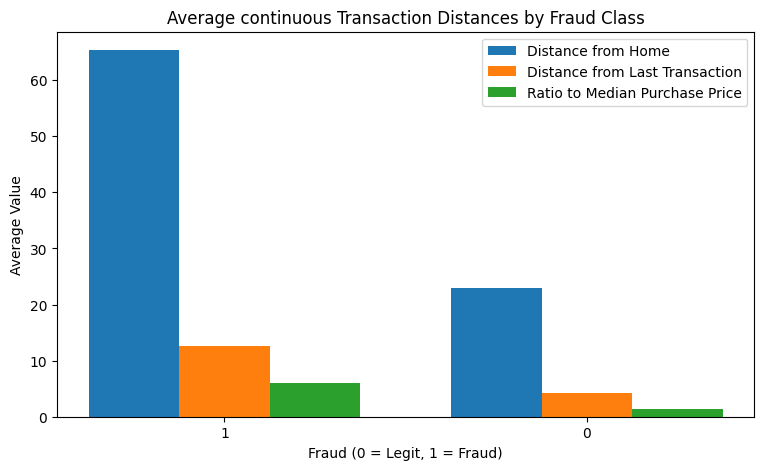

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fraud = grouped_pdf["fraud"]
x = np.arange(len(fraud))
width = 0.25

plt.figure(figsize=(9, 5))
plt.bar(x - width, grouped_pdf["avg(distance_from_home)"], width, label="Distance from Home")
plt.bar(x, grouped_pdf["avg(distance_from_last_transaction)"], width, label="Distance from Last Transaction")
plt.bar(x + width, grouped_pdf["avg(ratio_to_median_purchase_price)"], width, label="Ratio to Median Purchase Price")

plt.xticks(x, fraud)
plt.xlabel("Fraud (0 = Legit, 1 = Fraud)")
plt.ylabel("Average Value")
plt.title("Average continuous Transaction Distances by Fraud Class")
plt.legend()
plt.show()

The binary variables based on fraud

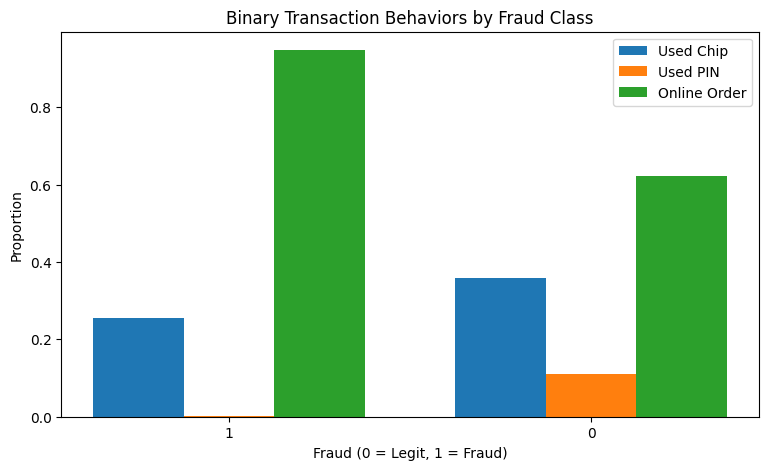

In [ ]:
width = 0.25

plt.figure(figsize=(9, 5))
plt.bar(x - width, grouped_pdf["avg(used_chip)"], width, label="Used Chip")
plt.bar(x, grouped_pdf["avg(used_pin_number)"], width, label="Used PIN")
plt.bar(x + width, grouped_pdf["avg(online_order)"], width, label="Online Order")

plt.xticks(x, fraud)
plt.xlabel("Fraud (0 = Legit, 1 = Fraud)")
plt.ylabel("Proportion")
plt.title("Binary Transaction Behaviors by Fraud Class")
plt.legend()
plt.show()

###2.3 Investigating class imbalance in the fraud classes

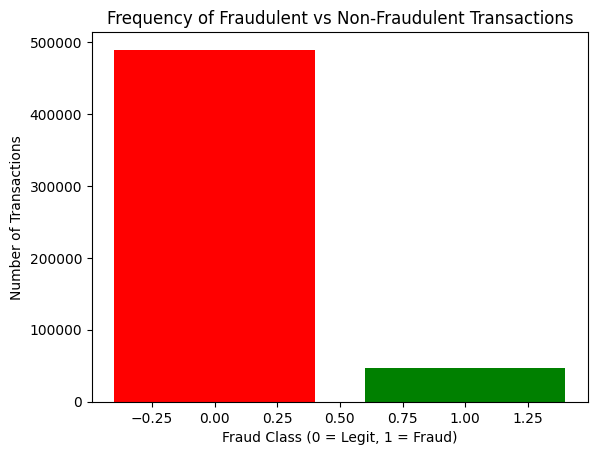

In [ ]:
# Count transactions by fraud class
fraud_counts = df.groupBy("fraud").count().toPandas()

plt.bar(fraud_counts["fraud"], fraud_counts["count"], color=["green", "red"])
plt.title("Frequency of Fraudulent vs Non-Fraudulent Transactions")
plt.xlabel("Fraud Class (0 = Legit, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

#3. Machine learning classification

##3.1. Preparing the dataset


In [ ]:
df.printSchema()

root
 |-- distance_from_home: double (nullable = true)
 |-- distance_from_last_transaction: double (nullable = true)
 |-- ratio_to_median_purchase_price: double (nullable = true)
 |-- repeat_retailer: integer (nullable = true)
 |-- used_chip: integer (nullable = true)
 |-- used_pin_number: integer (nullable = true)
 |-- online_order: integer (nullable = true)
 |-- fraud: integer (nullable = true)
 |-- distance_vector: vector (nullable = true)
 |-- scaled_distances: vector (nullable = true)
 |-- ratio_vector: vector (nullable = true)
 |-- normalized_ratio: vector (nullable = true)
 |-- final_features: vector (nullable = true)



In [ ]:
df_model = df.withColumnRenamed('fraud','label')

##3.2 Train/test split (stratified sampling)

Splitting the data set

In [ ]:
train_df, test_df = df_model.randomSplit([0.8, 0.2], seed=42)

Checking the distribution

In [ ]:
train_df.groupBy("label").count().show()
test_df.groupBy("label").count().show()

+-----+------+
|label| count|
+-----+------+
|    1| 37570|
|    0|391180|
+-----+------+

+-----+-----+
|label|count|
+-----+-----+
|    1| 9224|
|    0|98136|
+-----+-----+



##3.3. Training the model(Random forest classifier)

In [ ]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(featuresCol='final_features', labelCol='label',numTrees=20, maxDepth=5, seed= 42)
rf_model = rf.fit(train_df)


##3.4. The predictions

In [ ]:
rf_predictions = rf_model.transform(test_df)

rf_predictions.select(
    "label",
    "prediction",
    "probability"
).show(10)

+-----+----------+--------------------+
|label|prediction|         probability|
+-----+----------+--------------------+
|    0|       0.0|[0.98967977921479...|
|    0|       0.0|[0.98967977921479...|
|    0|       0.0|[0.98967977921479...|
|    1|       1.0|[0.37661086409256...|
|    1|       1.0|[0.37661086409256...|
|    0|       0.0|[0.98967977921479...|
|    0|       0.0|[0.98967977921479...|
|    0|       0.0|[0.98967977921479...|
|    0|       0.0|[0.98967977921479...|
|    0|       0.0|[0.98967977921479...|
+-----+----------+--------------------+
only showing top 10 rows


The prediction output contains the actual class label, the predicted class generated by the model, and a probability vector representing the likelihood of each class. The predicted class corresponds to the label with the highest probability.

##3.5. Evaluating the model

### Accuracy

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

accuracy_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
accuracy = accuracy_eval.evaluate(rf_predictions)
print('Accuracy:', accuracy)

Accuracy: 0.9403036512667661


###Precision

In [ ]:
precision_eval= MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision")
precision = precision_eval.evaluate(rf_predictions)
print('Precision:', precision)

Precision: 0.9461062477333195


###Recall

In [ ]:
recall_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall")
recall = recall_eval.evaluate(rf_predictions)
print('Recall:', recall)


Recall: 0.940303651266766


###F1 score

In [ ]:
f1_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
f1 = f1_eval.evaluate(rf_predictions)
print('F1 score:', f1)

F1 score: 0.9426677366295766


##3.6 Confusion matrix

To show how the model performs overall

In [ ]:
rf_predictions.groupBy('label','prediction').count().show()

+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|    1|       0.0| 2310|
|    0|       0.0|94037|
|    1|       1.0| 6914|
|    0|       1.0| 4099|
+-----+----------+-----+



#3.7.  ROC curve

Evaluates the model’s ability to distinguish between fraudulent and legitimate transactions by plotting the true positive rate against the false positive rate.

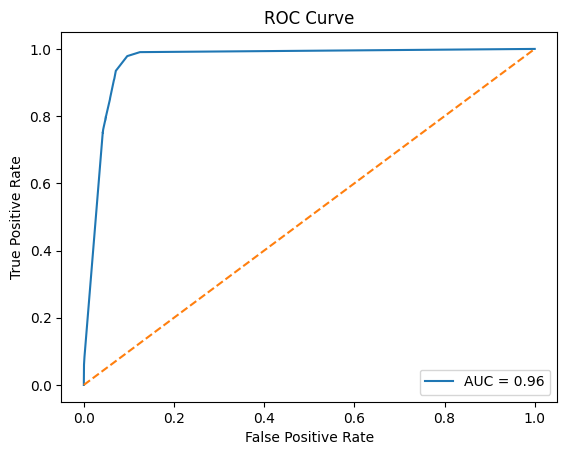

In [ ]:
from sklearn.metrics import roc_curve, auc

pdf = rf_predictions.select("label", "probability").toPandas()

pdf["prob_fraud"] = pdf["probability"].apply(lambda x: x[1])

fpr, tpr, _ = roc_curve(pdf["label"], pdf["prob_fraud"])
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = %0.2f" % roc_auc)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()